# Practical Lecture: Unsupervised Learning on 1 Lakh (100,000) Real-World Rows

Welcome to class! Today we are going to learn **Unsupervised Learning** — not just the theory, but by getting our hands dirty with a **real-world dataset of 1,00,000 (1 lakh) rows**.

### What You Will Learn Today
1. **What Unsupervised Learning actually is** (using a simple everyday analogy).
2. **How to load and save 1,00,000 real rows** (no fake/synthetic data!).
3. **Why Feature Scaling is mandatory** before clustering.
4. **PCA (Principal Component Analysis):** Compressing many columns into 2D so we can *see* our data.
5. **K-Means Clustering:** Finding hidden groups + picking the best $K$ using the Elbow Method & Silhouette Score.
6. **DBSCAN:** Finding oddly shaped clusters and spotting outliers.
7. **Homework Exercises** to test your skills!

---
## 1. The Core Idea: Learning Without an Answer Key

Think about how you study for an exam:
- **Supervised Learning** is like studying with a **teacher and an answer key**. Every row has a label (e.g., *Spam* vs. *Not Spam*, or *House Price = $300k*).
- **Unsupervised Learning** is like being handed a **giant box of mixed LEGO bricks with no instructions**. Nobody tells you the categories. Your job is to look at the shapes, sizes, and colors and **organize them into meaningful groups yourself**.

### The 3 Main Superpowers of Unsupervised Learning
| Technique | Plain-English Goal | Real-World Example |
| :--- | :--- | :--- |
| **Clustering** (K-Means, DBSCAN) | Group similar items together | Grouping 1 lakh shoppers into "Budget", "VIP", and "Weekend" buyers |
| **Dimensionality Reduction** (PCA) | Compress 50+ columns into 2–3 columns without losing the big picture | Visualizing complex sensor or customer data on a 2D screen |
| **Anomaly Detection** | Spot rare, weird data points that don't fit any group | Catching fraudulent credit card swipes |

---
## 2. Loading Our Real-World Dataset (1 Lakh / 100,000 Rows)

We will use the **Forest Covertype Dataset** from the US Forest Service (built into `scikit-learn` via [`fetch_covtype`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_covtype.html)).
- **Total real rows available:** 581,012 observations of 30×30 meter forest patches in Colorado, USA.
- **What each row measures:** Elevation, Aspect (compass direction), Slope, Distance to Water/Roadways/Fire Points, Hillshade at 9am/Noon/3pm, plus Wilderness & Soil indicators.
- **Why it's great for class:** It is 100% real-world environmental data, completely free, and loads in 1 line of Python without needing a Kaggle login.

> **Note:** We will sample **exactly 1,00,000 rows** (`100_000`), remove the `Cover_Type` label column (because unsupervised learning doesn't use labels!), and save it as `real_dataset_1lakh.csv` on your computer.
>
> *Want to try a business/e-commerce dataset for extra practice later? Check out the [UCI Online Retail Dataset](https://archive.ics.uci.edu/dataset/352/online+retail) (541,909 real UK retail transactions).*

In [1]:
# Step 1: Import our essential Python libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_covtype
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

# Make plots look clean and readable
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
# Step 2: Fetch the real dataset and take a reproducible 1 Lakh (100,000) row sample
print("Downloading/loading Forest Covertype dataset (this takes a few seconds the first time)...")
cov = fetch_covtype(as_frame=True)
full_df = cov.data  # Only the 54 feature columns (no target label!)

# Sample exactly 1,00,000 rows
df_1lakh = full_df.sample(n=100_000, random_state=42).reset_index(drop=True)

# Save to CSV so you have your 1-lakh real dataset file ready!
csv_filename = "real_dataset_1lakh.csv"
df_1lakh.to_csv(csv_filename, index=False)

print(f"Done! Dataset shape: {df_1lakh.shape[0]:,} rows x {df_1lakh.shape[1]} columns")
print(f"Saved locally as: {csv_filename}")
df_1lakh.head()

Downloading/loading Forest Covertype dataset (this takes a few seconds the first time)...
Done! Dataset shape: 100,000 rows x 54 columns
Saved locally as: real_dataset_1lakh.csv


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type_30,Soil_Type_31,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39
0,3351.0,206.0,27.0,726.0,124.0,3813.0,192.0,252.0,180.0,2271.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2732.0,129.0,7.0,212.0,1.0,1082.0,231.0,236.0,137.0,912.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2572.0,24.0,9.0,201.0,25.0,957.0,216.0,222.0,142.0,2191.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2824.0,69.0,13.0,417.0,39.0,3223.0,233.0,214.0,110.0,6478.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2529.0,84.0,5.0,120.0,9.0,1092.0,227.0,231.0,139.0,4983.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


---
## 3. Quick EDA & Why Feature Scaling Is Mandatory

Let's inspect the first 10 continuous measurement columns. Notice something huge:
- `Elevation` is measured in meters (~2,000 to 3,800).
- `Slope` is measured in degrees (~0 to 60).
- `Horizontal_Distance_To_Roadways` can be 5,000+ meters!

### Teacher's Golden Rule of Clustering:
Algorithms like **K-Means** and **PCA** measure **straight-line (Euclidean) distance** between rows.
If we don't scale our columns first, a column with big numbers like `Elevation` (3,000) will completely bully a column with small numbers like `Slope` (15).

**Fix:** We use `StandardScaler` so every column has **Mean = 0** and **Standard Deviation = 1**. Now every feature gets an equal voice!

For clean clustering, let's focus on the **10 continuous physical measurements** (columns 0 to 9).

In [3]:
# Select the 10 continuous physical measurement columns
continuous_cols = [
    "Elevation", "Aspect", "Slope",
    "Horizontal_Distance_To_Hydrology", "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points"
]

X = df_1lakh[continuous_cols].copy()

print("Missing values per column:")
print(X.isnull().sum())

print("\nSummary statistics BEFORE scaling:")
display(X.describe().round(2))

Missing values per column:
Elevation                             0
Aspect                                0
Slope                                 0
Horizontal_Distance_To_Hydrology      0
Vertical_Distance_To_Hydrology        0
Horizontal_Distance_To_Roadways       0
Hillshade_9am                         0
Hillshade_Noon                        0
Hillshade_3pm                         0
Horizontal_Distance_To_Fire_Points    0
dtype: int64

Summary statistics BEFORE scaling:


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points
count,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00
mean,2961.09,156.03,14.14,270.19,46.58,2353.24,212.07,223.34,142.61,1982.96
std,279.13,111.98,7.51,213.41,58.49,1559.14,26.86,19.78,38.47,1321.44
min,1871.00,0.00,0.00,0.00,-173.00,0.00,0.00,0.00,0.00,0.00
25%,2811.00,59.00,9.00,108.00,7.00,1110.00,198.00,213.00,119.00,1025.00
50%,2997.00,128.00,13.00,218.00,30.00,2007.00,218.00,226.00,143.00,1717.00
75%,3165.00,261.00,18.00,390.00,69.00,3323.00,231.00,237.00,169.00,2557.00
max,3846.00,360.00,65.00,1383.00,598.00,7087.00,254.00,254.00,253.00,7172.00


In [4]:
# Scale the 1,00,000 rows using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert back to a DataFrame just to verify Mean ~ 0 and Std ~ 1
X_scaled_df = pd.DataFrame(X_scaled, columns=continuous_cols)
print("Summary statistics AFTER scaling (notice mean ~ 0 and std ~ 1):")
display(X_scaled_df.describe().round(2))

Summary statistics AFTER scaling (notice mean ~ 0 and std ~ 1):


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points
count,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00
mean,0.00,-0.00,0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-3.91,-1.39,-1.88,-1.27,-3.75,-1.51,-7.90,-11.29,-3.71,-1.50
25%,-0.54,-0.87,-0.68,-0.76,-0.68,-0.80,-0.52,-0.52,-0.61,-0.72
50%,0.13,-0.25,-0.15,-0.24,-0.28,-0.22,0.22,0.13,0.01,-0.20
75%,0.73,0.94,0.51,0.56,0.38,0.62,0.70,0.69,0.69,0.43
max,3.17,1.82,6.78,5.21,9.43,3.04,1.56,1.55,2.87,3.93


---
## 4. Dimensionality Reduction with PCA (Compressing 10 Features into 2D)

Humans can easily see 2D or 3D plots, but we **cannot** see a 10-dimensional graph!
**PCA (Principal Component Analysis)** rotates our data and finds the best new axes (called *Principal Components*) that capture the maximum possible information (variance).

Think of it like taking a photograph of a 3D statue: if you stand at the right angle, a 2D photo still shows almost everything important about the statue!

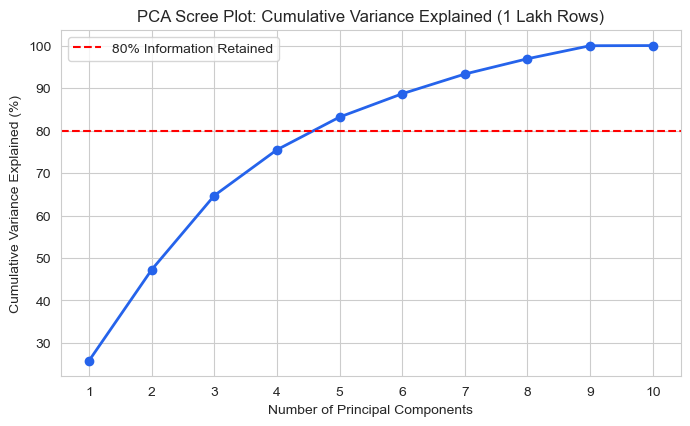

Top  1 components keep 25.86% of total information
Top  2 components keep 47.26% of total information
Top  3 components keep 64.71% of total information
Top  4 components keep 75.48% of total information
Top  5 components keep 83.18% of total information
Top  6 components keep 88.66% of total information
Top  7 components keep 93.30% of total information
Top  8 components keep 96.90% of total information
Top  9 components keep 99.96% of total information
Top 10 components keep 100.00% of total information


In [5]:
# Fit PCA on all 10 scaled features to see how much information each component keeps
pca_full = PCA()
pca_full.fit(X_scaled)

cum_variance = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(cum_variance) + 1), cum_variance * 100, marker="o", linewidth=2, color="#2563eb")
plt.axhline(80, color="red", linestyle="--", label="80% Information Retained")
plt.title("PCA Scree Plot: Cumulative Variance Explained (1 Lakh Rows)")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Variance Explained (%)")
plt.xticks(range(1, 11))
plt.legend()
plt.show()

for i, var in enumerate(cum_variance, start=1):
    print(f"Top {i:2d} components keep {var*100:.2f}% of total information")

In [6]:
# Project our 1,00,000 rows down to 2D so we can visualize them later
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_scaled)

print(f"2D PCA shape: {X_pca.shape}")
print(f"Information kept in 2D: {pca_2d.explained_variance_ratio_.sum()*100:.2f}%")

2D PCA shape: (100000, 2)
Information kept in 2D: 47.26%


---
## 5. K-Means Clustering (Grouping Our 1 Lakh Forest Patches)

### How K-Means Works in 3 Simple Steps
1. **Pick $K$ random centers** (centroids) on the map.
2. **Assign** every single one of our 1,00,000 rows to its nearest center.
3. **Move** each center to the average position of its assigned points, and repeat until the groups stop changing!

### How Do We Choose the Best $K$?
We test $K = 2, 3, \dots, 8$ and look at two clues:
1. **Elbow Method (Inertia):** Measures how tightly packed the clusters are (lower = tighter). We look for the "elbow" bend where adding more clusters stops helping much.
2. **Silhouette Score:** Measures how well-separated the clusters are (from `-1` to `+1`; higher = cleaner separation). *Tip: Silhouette Score is slow on 1 lakh rows, so we compute it on a 10,000-row sample!*

K=2 | Inertia: 795,982 | Silhouette Score: 0.2188
K=3 | Inertia: 699,450 | Silhouette Score: 0.1797
K=4 | Inertia: 631,853 | Silhouette Score: 0.1841
K=5 | Inertia: 575,675 | Silhouette Score: 0.1776
K=6 | Inertia: 529,560 | Silhouette Score: 0.1757
K=7 | Inertia: 502,784 | Silhouette Score: 0.1581
K=8 | Inertia: 478,932 | Silhouette Score: 0.1607


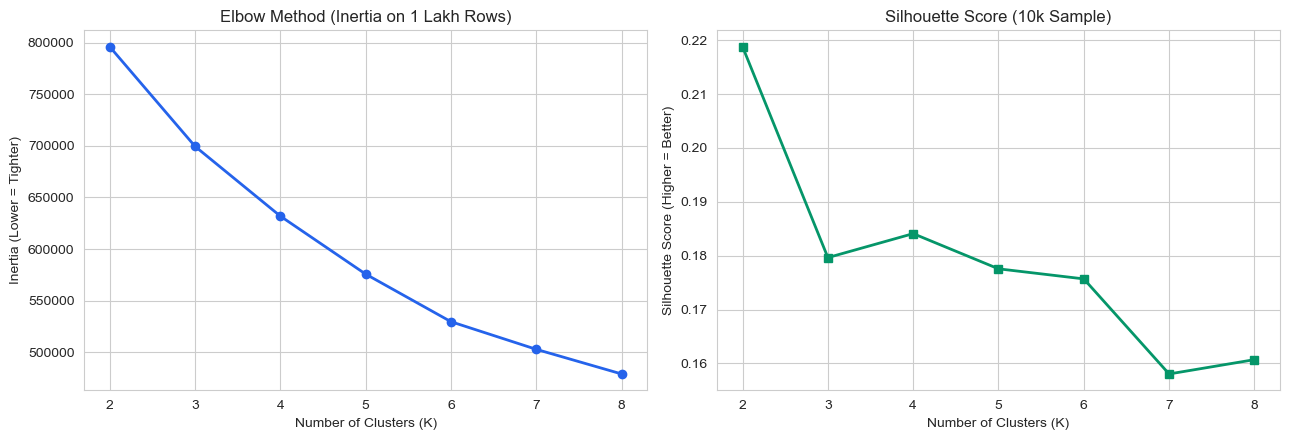

In [8]:
# Find the best K using Inertia (Elbow) on 1 lakh rows and Silhouette on a 10k sample
inertias = []
sil_scores = []
k_values = range(2, 9)

# 10,000-row sample for fast Silhouette calculation
np.random.seed(42)
sample_idx = np.random.choice(len(X_scaled), size=10_000, replace=False)
X_sample = X_scaled[sample_idx]

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_all = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    
    # Score on the 10k sample
    sil = silhouette_score(X_sample, labels_all[sample_idx])
    sil_scores.append(sil)
    print(f"K={k} | Inertia: {km.inertia_:,.0f} | Silhouette Score: {sil:.4f}")

# Plot Elbow & Silhouette side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(k_values, inertias, marker="o", color="#2563eb", linewidth=2)
axes[0].set_title("Elbow Method (Inertia on 1 Lakh Rows)")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia (Lower = Tighter)")

axes[1].plot(k_values, sil_scores, marker="s", color="#059669", linewidth=2)
axes[1].set_title("Silhouette Score (10k Sample)")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score (Higher = Better)")

plt.tight_layout()
plt.show()

How many rows landed in each cluster?
KMeans_Cluster
0    27226
1    41577
2    13408
3    17789
Name: count, dtype: int64


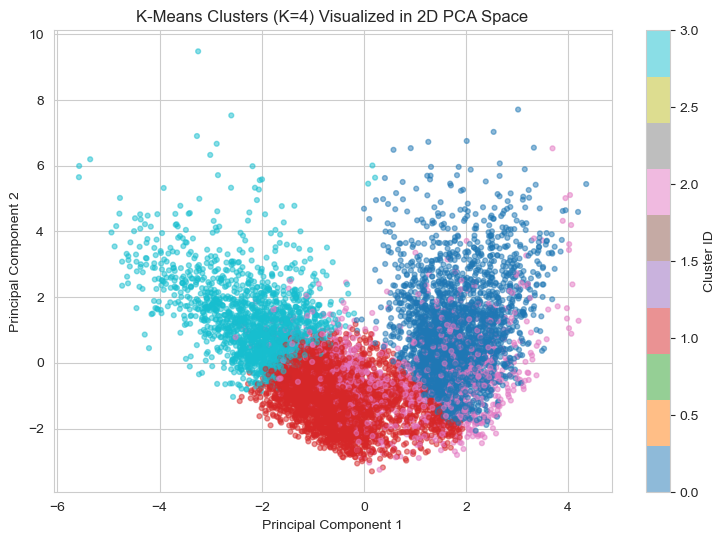

In [9]:
# Fit our final K-Means model (let's use K=4 as a balanced, interpretable choice)
best_k = 4
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df_1lakh["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("How many rows landed in each cluster?")
print(df_1lakh["KMeans_Cluster"].value_counts().sort_index())

# Visualize the clusters in 2D PCA space (plotting 10,000 points so the plot stays crisp!)
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_pca[sample_idx, 0],
    X_pca[sample_idx, 1],
    c=df_1lakh["KMeans_Cluster"].iloc[sample_idx],
    cmap="tab10",
    alpha=0.5,
    s=12
)
plt.colorbar(scatter, label="Cluster ID")
plt.title(f"K-Means Clusters (K={best_k}) Visualized in 2D PCA Space")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In [10]:
# Teacher's Step: ALWAYS interpret what each cluster actually means in real life!
cluster_profile = df_1lakh.groupby("KMeans_Cluster")[continuous_cols].mean().round(1)
print("Average feature values per cluster (1 Lakh Rows):")
display(cluster_profile)

Average feature values per cluster (1 Lakh Rows):


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points
KMeans_Cluster,,,,,,,,,,
0,2913.0,296.3,16.4,211.7,40.6,2157.1,181.7,229.3,183.3,1565.0
1,2990.8,96.1,9.8,206.7,20.0,2698.2,225.6,228.2,134.7,2417.0
2,3168.6,172.4,13.0,635.3,133.2,2798.1,211.2,230.4,152.0,2125.6
3,2809.0,69.0,21.5,232.8,52.5,1511.9,227.4,197.6,91.8,1500.9


---
## 6. DBSCAN: Density-Based Clustering (Handling Odd Shapes & Outliers)

K-Means assumes clusters are roughly **round balls**. What if your data has crescent shapes, long trails, or noisy outliers?

**DBSCAN** works differently:
- It looks for **crowded neighborhoods** (points packed closely together within distance `eps`).
- Any point sitting all alone in an empty area gets labeled **`-1` (Noise / Outlier)**!

### Practical Engineering Tip for 1 Lakh Rows:
Standard DBSCAN can use a lot of memory if it builds a 100,000 × 100,000 distance matrix. So in practice, data scientists either tune `eps` on a **15,000-row sample** or use `K-Means` / `MiniBatchKMeans` for 100k+ rows.

DBSCAN Cluster Counts (-1 means Noise/Outliers):
  Cluster -1: 152 points
  Cluster  0: 14,848 points


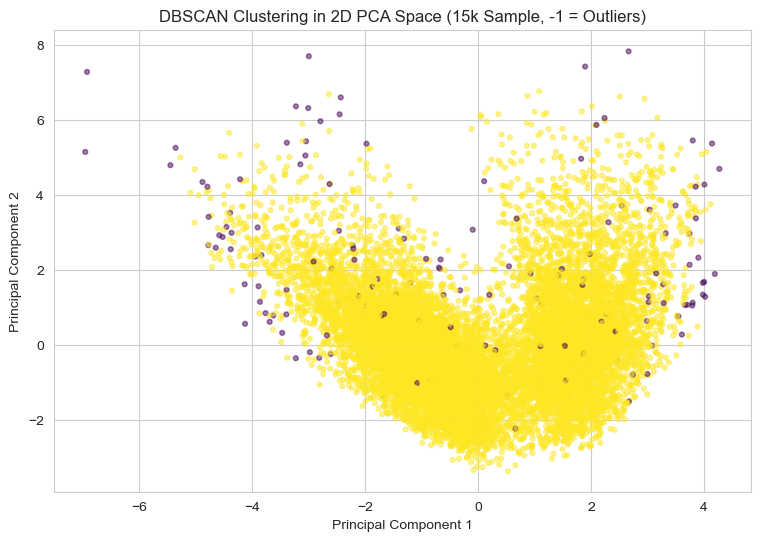

In [11]:
# Run DBSCAN on a 15,000-row sample
db_idx = np.random.choice(len(X_scaled), size=15_000, replace=False)
X_db = X_scaled[db_idx]

dbscan = DBSCAN(eps=1.8, min_samples=15)
db_labels = dbscan.fit_predict(X_db)

unique_labels, counts = np.unique(db_labels, return_counts=True)
print("DBSCAN Cluster Counts (-1 means Noise/Outliers):")
for lbl, cnt in zip(unique_labels, counts):
    print(f"  Cluster {lbl:2d}: {cnt:,} points")

plt.figure(figsize=(9, 6))
plt.scatter(X_pca[db_idx, 0], X_pca[db_idx, 1], c=db_labels, cmap="viridis", alpha=0.5, s=12)
plt.title("DBSCAN Clustering in 2D PCA Space (15k Sample, -1 = Outliers)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

---
## 7. Your Turn! Student Homework & Practice Exercises

Try these 3 quick exercises right below to cement what you learned:
1. **Change $K$:** Re-run K-Means with `best_k = 3` and `best_k = 5`. Look at the `cluster_profile` table — which $K$ tells the clearest story about elevation, slope, and distance to roads?
2. **Add Binary Features:** Try including the 4 `Wilderness_Area` columns in `X` and compare the clusters.
3. **Try a Business Dataset:** Download the [UCI Online Retail Dataset](https://archive.ics.uci.edu/dataset/352/online+retail), compute **Recency, Frequency, Monetary (RFM)** per customer, and run K-Means to find your VIP shoppers!